In [1]:
import modin.pandas as pd, numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import chess
from torch.utils.data import DataLoader
from tqdm import tqdm, trange
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from dataset import ChessDataset, ConcatDataset

In [2]:
# dataset0_d8 = ChessDataset('dataset0_d8.csv')
# dataset1_d8 = ChessDataset('dataset1_d8.csv')  # target
# m = len(dataset1_d8)
# m_train = int(.8 * m)
# dataset1_d8_train = ChessDataset('dataset1_d8.csv', i_to=m_train)
# dataset1_d8_test = ChessDataset('dataset1_d8.csv', i_from=m_train)
# dataset2_d6 = ChessDataset('dataset_d6.csv')
# dataset4_d8 = ChessDataset('dataset2nn_d8.csv')
# #dataset3_d4 = ChessDataset('dataset_d4.csv')
# #dataset4_d5 = ChessDataset('dataset_d5.csv')
# #n = len(dataset)O
# #dataset[0]
# #together_train_d4 = dataset3_d4
# together_train_d6 = dataset2_d6
# together_train_d8 = ConcatDataset([dataset0_d8, dataset1_d8_train, dataset4_d8])
# together_train = ConcatDataset([together_train_d6, together_train_d8])
# print(f'train {len(together_train)/1e6}M, test {len(dataset1_d8_test)/1e6}M')

folder = 'datasets/'
# dataset00_d4 = ChessDataset(folder+'dataset00_d4.csv')
# dataset01_d4 = ChessDataset(folder+'dataset01_d4.csv')
# dataset02_d4_old = ChessDataset(folder+'dataset02_d4_old.csv')
#dataset02_d6_old = ChessDataset(folder+'dataset02_d6_old.csv')
#dataset02_d8_old = ChessDataset(folder+'dataset02_d8_old.csv')
# dataset02_d4 = ChessDataset(folder+'dataset02_d4.csv')
# last_filename = folder+'dataset02_d8_1.csv'

# dataset03_d4_0 = ChessDataset(folder+'dataset03_d4_0.csv')
# dataset03_d4 = ChessDataset(folder+'dataset03_d4.csv')
# dataset03_d6 = ChessDataset(folder+'dataset03_d6.csv')
# dataset04_d8 = ChessDataset(folder+'dataset04_d8.csv')
# dataset05_d8 = ChessDataset(folder+'dataset05_d8.csv')
# dataset06_d4 = ChessDataset(folder+'dataset06_d4.csv')

halfKP = False
# dataset07_d6 = ChessDataset(folder+'dataset07_d6.csv', halfKP)

# dataset06_d8 = ChessDataset(folder+'dataset06_d8_processed.csv', halfKP)
# dataset07_d8 = ChessDataset(folder+'dataset07_d8_processed.csv', halfKP)
# dataset08_d8_1 = ChessDataset(folder+'dataset08_d8_1_processed.csv', halfKP)
# dataset08_d8_2 = ChessDataset(folder+'dataset08_d8_2_processed.csv', halfKP)
# dataset09_d8_0 = ChessDataset(folder+'dataset09_d8_0_processed.csv', halfKP)
# dataset09_d8_1 = ChessDataset(folder+'dataset09_d8_1_processed.csv', halfKP)
dataset09_d8_2 = ChessDataset(folder+'dataset09_d8_2_processed.csv',halfKP)
last_filename = folder+'dataset09_d8_3.csv'
dataset_last = ChessDataset(last_filename, halfKP)
n = len(dataset_last)
n_train = int(.8 * n)
dataset_last_train = ChessDataset(last_filename, halfKP, i_to=n_train)
dataset_last_test = ChessDataset(last_filename, halfKP, i_from=n_train)
# together_train_1 = ConcatDataset([dataset06_d8, dataset07_d8,
#                                   dataset08_d8_1, dataset08_d8_2, dataset09_d8_0, dataset09_d8_1,
# ])
together_train_1 = None
together_train_2 = dataset_last_train
together_test = dataset_last_test
print(f'train {(len(together_train_1 or [])+len(together_train_2))/1e6}M, test {len(together_test)/1e6}M')

Caricamento dataset... halfKP=False
calibration info: np.abs(self.y_evals[:,-1]).mean()=np.float64(576.9857372728163), self.y_evals[:,-1].std()=np.float64(1614.4847581388622), self.y_evals[:,-1][np.abs(self.y_evals[:,-1])<400].std()=np.float64(202.0174682652614)
DATASET at depth 8
Posizioni totali: 22792905, vittorie bianco 2739987, vittorie nero 2863558, patte: 17189361
Caricamento dataset... halfKP=False
calibration info: np.abs(self.y_evals[:,-1]).mean()=np.float64(nan), self.y_evals[:,-1].std()=np.float64(nan), self.y_evals[:,-1][np.abs(self.y_evals[:,-1])<400].std()=np.float64(214.4636616576691)
DATASET at depth 8
Posizioni totali: 13206193, vittorie bianco 1224101, vittorie nero 1212670, patte: 10769422
Caricamento dataset... halfKP=False
calibration info: np.abs(self.y_evals[:,-1]).mean()=np.float64(1636.7327123241616), self.y_evals[:,-1].std()=np.float64(2642.5483630073295), self.y_evals[:,-1][np.abs(self.y_evals[:,-1])<400].std()=np.float64(213.69120775728842)
DATASET at depth

In [ ]:
# b = chess.Board(X_fen[0])
# b.piece_at(chess.square(0,0))

# from joblib import Parallel, delayed

# # def process_fen(fen):
# #     b = chess.Board(fen)
# #     bb = [b.pieces(p, c) for c in (1, 0) for p in range(1, 7)]
# #     bits = ((np.array(bb, dtype=np.uint64)[:, None] >> np.arange(64, dtype=np.uint64)) & 1).ravel()
# #     meta = [b.has_kingside_castling_rights(1), b.has_queenside_castling_rights(1),
# #             b.has_kingside_castling_rights(0), b.has_queenside_castling_rights(0),
# #             0 #b.ep_square or -1
# #            ]
# #     return np.concatenate([bits, meta])

# # X_pos = torch.tensor(np.array(Parallel(n_jobs=-1)(delayed(process_fen)(f) for f in X_fen)), dtype=torch.float)

# def process_batch(fens):
#     shifts = np.arange(64, dtype=np.uint64)
#     batch_features = []
#     for fen in fens:
#         b = chess.Board(fen)
#         bb = np.array([b.pieces(p, c) for c in (1, 0) for p in range(1, 7)], dtype=np.uint64)
#         bits = ((bb[:, None] >> shifts) & 1).ravel()
#         meta = [b.has_kingside_castling_rights(1), b.has_queenside_castling_rights(1),
#                 b.has_kingside_castling_rights(0), b.has_queenside_castling_rights(0), b.ep_square != -1]
#         batch_features.append(np.concatenate([bits, meta]))
#     return np.array(batch_features, dtype=np.bool)

# n_workers = 24
# batches = np.array_split(X_fen, n_workers)

# results = list(map(torch.tensor, Parallel(n_jobs=n_workers)(delayed(process_batch)(batch) for batch in batches)))
# X_pos = torch.vstack(results)

# y_evals_dmax = torch.tensor(y_evals[:-1,0])
# fine = torch.cat([torch.full(y_evals_dmax.shape,True), torch.tensor([False])]) # (-500 <= y_evals_dmax) & (y_evals_dmax <= +500)
# m = fine.sum()
# m_train = int(.8 * m)
# print(m,n)
# v0, v1 = torch.tensor(y_evals[fine,0],dtype=torch.float), torch.tensor(y_evals[fine,-1],dtype=torch.float)
# torch.dot(v0,v1)/torch.norm(v0)**2

# X = X_pos[fine]
# Lambda = 0.5
# y = Lambda * (2*torch.sigmoid(torch.tensor(y_evals[fine,-1])/400)-1) + (1 - Lambda) * torch.tensor(y_outcome[fine])
# y, y.min(), y.max(), y.mean(), y.std()

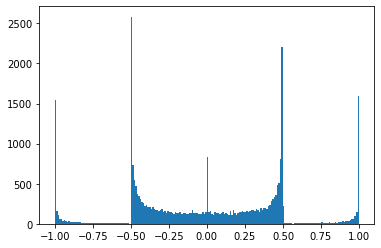

In [4]:
plt.hist([together_train_2[i][1] for i in np.random.randint(len(together_train_2),size=30000)], bins=200)
plt.show()

In [9]:
device = 'cuda'
# torch.set_float32_matmul_precision('high')
# class NNModel(nn.Module):
#     def __init__(self):
#         super().__init__()
#         self.fc1 = nn.Linear(in_features=768+5, out_features=128)
# #         self.fc2 = nn.Linear(in_features=16, out_features=16)
# #         self.fc3 = nn.Linear(in_features=16, out_features=16)
# #         self.fc4 = nn.Linear(in_features=16, out_features=1)
#         self.stack = nn.Sequential(
#             nn.ReLU(),
#             nn.Linear(in_features=128, out_features=8),
#             nn.ReLU(),
#             nn.Linear(in_features=8, out_features=8),
#             nn.ReLU(),
#             nn.Linear(in_features=8, out_features=1)
#         )
#     def forward(self, x):
#         q_step = self.fc1.weight.abs().max() / 32767
#         w_quant = torch.round(self.fc1.weight / q_step) * q_step
#         # Straight-Through Estimator: utilise les poids quantifiés pour le calcul,
#         # mais laisse passer le gradient intact vers les poids réels pour Adam
#         w_ste = self.fc1.weight + (w_quant - self.fc1.weight).detach()
#         x = F.linear(x, w_ste, self.fc1.bias)
# #         x = F.relu(x)
# #         w_quant = torch.round(self.fc2.weight / q_step) * q_step
#         return self.stack(x)
# nn_model = torch.compile(NNModel().to(device))

nn_model = nn.Sequential(
    nn.Linear(in_features=773, out_features=128),  # 772+40960:773
    nn.ReLU(),
    nn.Linear(in_features=128, out_features=8),
    nn.ReLU(),
    nn.Linear(in_features=8, out_features=8),
    nn.ReLU(),
    nn.Linear(in_features=8, out_features=1)
).to(device)
nn_model.load_state_dict(torch.load('models/model_v9_128_8_8.pth'))
with torch.no_grad():
    last_layer = list(nn_model.children())[-1]
    last_layer.weight *= 2
    last_layer.bias *= 2
# nn_model.load_state_dict(torch.load('model10a2_tmp.pth'))
# with torch.no_grad():
#     ch, ch_s = list(nn_model.children()), list(nn_model_s.children())
#     ch[0].weight[:,:772] = ch_s[0].weight[:,:772] / 2
#     ch[0].weight[:,320:384] = ch_s[0].weight[:,320:384]  # restore kings' weights, as they won't be in HalfKP
#     ch[0].weight[:,704:772] = ch_s[0].weight[:,704:772]
#     for i in range(64):
#         p = 772 + i * 640
#         ch[0].weight[:,p:p+320] = ch_s[0].weight[:,:320] / 2
#         ch[0].weight[:,p+320:p+640] = ch_s[0].weight[:,384:704] / 2
#     ch[0].bias.copy_(ch_s[0].bias)
#     ch[2].weight.copy_(ch_s[2].weight)
#     ch[2].bias.copy_(ch_s[2].bias)
#     ch[4].weight.copy_(ch_s[4].weight)
#     ch[4].bias.copy_(ch_s[4].bias)
#     ch[6].weight.copy_(ch_s[6].weight)
#     ch[6].bias.copy_(ch_s[6].bias)

B = 512
train_dataloader_1 = None#DataLoader(together_train_1, B, True, num_workers=24, pin_memory=True, drop_last=False)
train_dataloader_2 = DataLoader(together_train_2, B, True, num_workers=24, pin_memory=True, drop_last=False)
# train_dataloader = DataLoader(together_train, B, True, num_workers=24, pin_memory=True, drop_last=False)
test_dataloader = DataLoader(together_test, B, True, num_workers=24, pin_memory=True, drop_last=False)

def save_model(model,name):
    torch.save(nn_model.state_dict(), 'models/'+name+'.pth')
    state = nn_model.state_dict()
    def get_w(name):
        return np.ascontiguousarray(state[name].cpu().numpy().T, dtype=np.float32)
    def get_b(name):
        return np.ascontiguousarray(state[name].cpu().numpy(), dtype=np.float32)
    w01 = get_w('0.weight')
    b1  = get_b('0.bias')
    w12 = get_w('2.weight')
    b2  = get_b('2.bias')
    w23 = get_w('4.weight')
    b3  = get_b('4.bias')
    w34 = get_w('6.weight')
    b4  = get_b('6.bias')
    with open('models/'+name+'.bin', 'wb') as f:
        w01.tofile(f)
        b1.tofile(f)
        w12.tofile(f)
        b2.tofile(f)
        w23.tofile(f)
        b3.tofile(f)
        w34.tofile(f)
        b4.tofile(f)
    w01.shape, b1.shape
    print(f'model {name}.bin/pth saved')

#1e-4,1e-5
#1e-5,1e-5 for 10a0
optimizer = torch.optim.Adam(nn_model.parameters(), 1e-5, weight_decay=1e-4)  # wd was 3e-5, then 1e-6 for v6.*, 2e-4 for v7.*
gamma = 1 - .3 / (len(train_dataloader_1 or []) + len(train_dataloader_2 or []))  # e²≈7.4, e³≈20, e⁴≈55
lr_scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma)

losses = []
nn_model.eval()
with torch.no_grad():
    for X, y in tqdm(test_dataloader):
        y_batch_pred = nn_model(X.float().to(device))
        y_batch_true = y.to(device).view(-1, 1)
        loss = F.mse_loss(y_batch_pred, y_batch_true)
        losses.append(loss.item())
print(f'before training test loss {np.mean(losses)}')

epoch_train_losses, epoch_test_losses, best_test_loss = [], [], 1e9
for epoch_i in range(10):
    nn_model.train()
    nn_model.to(device)
    for train_dataloader_i, train_dataloader_ in enumerate([train_dataloader_2]):
        losses = []
        bar = tqdm(train_dataloader_)
        for i, (X, y) in enumerate(bar):
            y_batch_pred = nn_model(X.float().to(device))  #X[:,:768+5]
            y_batch_true = y.to(device).view(-1, 1)
            optimizer.zero_grad()
            loss = F.mse_loss(y_batch_pred, y_batch_true)
            loss.backward()
            losses.append(loss.item())
            optimizer.step()
            lr_scheduler.step()
            if i % 100 == 0:
                bar.set_description(f'loss={np.mean(losses[-100:]):.4f}, lr={lr_scheduler.get_last_lr()[0]:2f}')
#             if i % 100000 == 0:
#                 save_model(nn_model,f'model10b0_tmp')
        epoch_train_losses.append(np.mean(losses))
        print(f'epoch {epoch_i}-{train_dataloader_i} train loss {epoch_train_losses[-1]}')
    losses = []
    nn_model.eval()
    with torch.no_grad():
        for X, y in tqdm(test_dataloader):
            y_batch_pred = nn_model(X.float().to(device))
            y_batch_true = y.to(device).view(-1, 1)
            loss = F.mse_loss(y_batch_pred, y_batch_true)
            losses.append(loss.item())
    epoch_test_losses.append(np.mean(losses))
    print(f'epoch {epoch_i} test loss {epoch_test_losses[-1]}')
    if True or epoch_test_losses[-1] < best_test_loss:
        best_test_loss = epoch_test_losses[-1]
        save_model(nn_model,f'model9m{epoch_i}')
    
#nn_model(torch.tensor(X[0,:768]).view(1,12,8,8))
#plt.plot(np.mean(np.array(losses[:len(losses)//1000*1000]).reshape((-1,1000)), 1))
# plt.plot(epoch_train_losses)
# plt.plot(epoch_test_losses)
# plt.show()

100%|██████████████████████████████████████████████████████| 5159/5159 [00:20<00:00, 257.17it/s]


before training test loss 0.21304614713405032


loss=0.0502, lr=0.000007: 100%|██████████████████████████| 20635/20635 [01:24<00:00, 244.58it/s]


epoch 0-0 train loss 0.054205110625808225


100%|██████████████████████████████████████████████████████| 5159/5159 [00:19<00:00, 270.04it/s]


...

epoch 8 test loss 0.05406725547744175
model model9m8.bin/pth saved


loss=0.0455, lr=0.000000: 100%|██████████████████████████| 20635/20635 [01:27<00:00, 237.02it/s]


epoch 9-0 train loss 0.04551947427115141


100%|██████████████████████████████████████████████████████| 5159/5159 [00:19<00:00, 258.48it/s]

epoch 9 test loss 0.05403330975634041
model model9m9.bin/pth saved


In [38]:
from copy import deepcopy

with torch.no_grad():
    nn_model_2 = deepcopy(nn_model)
    ch = list(nn_model_2.children())
    ch[0].weight[0] = 3
list(nn_model_2.children())[0].weight

Parameter containing:
tensor([[ 3.0000e+00,  3.0000e+00,  3.0000e+00,  ...,  3.0000e+00,
          3.0000e+00,  3.0000e+00],
        [ 4.9261e-40,  5.0217e-40, -4.9558e-40,  ..., -4.9056e-40,
         -4.9147e-40,  4.9466e-40],
        [ 4.9378e-40, -4.9660e-40,  4.9722e-40,  ..., -4.9129e-40,
          4.9067e-40, -4.9281e-40],
        ...,
        [-5.0382e-40, -4.9395e-40, -5.0152e-40,  ..., -4.9960e-40,
         -4.9560e-40, -5.0033e-40],
        [-5.0232e-40,  4.9746e-40, -4.9715e-40,  ..., -4.9062e-40,
          4.9108e-40,  4.9093e-40],
        [-4.9783e-40,  5.0382e-40, -5.0117e-40,  ...,  2.0196e-04,
          4.9056e-40, -5.0183e-40]], device='cuda:0', requires_grad=True)

In [ ]:
#9f9 0.20493
# randomly inited is 0.240

In [27]:
save_model(nn_model,f'model10a1')

model model10a1.bin/pth saved


In [ ]:
d = torch.load('model_v9_128_8_8.pth')
plt.figure(figsize=(16,4))
plt.imshow(d['2.weight'].cpu().numpy())
plt.colorbar()
plt.show()

In [ ]:
fig, axes = plt.subplots(2, 6, figsize=(16,4))
for i in range(2):
    for j in range(6):
        p = (i * 6 + j) * 64
        axes[i,j].imshow(next(nn_model.parameters()).cpu().detach()[1,p:p+64].view(8,8).numpy())
        axes[i,j].set_title(['white','black'][i]+' '+'PNBRQK'[j])
#plt.colorbar()
plt.show()

In [ ]:
plt.hist(T.flatten().abs(), bins=100)
plt.show()

In [ ]:
fig, axes = plt.subplots(2, 6, figsize=(16,4))
for i in range(2):
    for j in range(6):
        p = (i * 6 + j) * 64
        axes[i,j].imshow(next(nn_model.parameters()).cpu().detach()[1,p:p+64].view(8,8).numpy())
#plt.colorbar()
plt.show()

In [ ]:
P = next(nn_model.parameters()).cpu().detach()[0].numpy() * 200
#P = np.log(2 / (P + 1) - 1) * -400
for i in range(6):
    print("{"+",".join(map(str,np.clip(np.round(P[i*64:i*64+64]-P[i*64:i*64+64].mean()),-127,+127)
                           .astype(int).tolist()))+"}")

In [ ]:
#[p.norm() for p in nn_model.parameters()]
#plt.imshow(next(nn_model.parameters()).cpu().detach()[:64].view(8,8).numpy())
fig, axes = plt.subplots(2, 6, figsize=(16,4))
for i in range(2):
    for j in range(6):
        p = (i * 6 + j) * 64
        axes[i,j].imshow(next(nn_model.parameters()).cpu().detach()[0,p:p+64].view(8,8).numpy())
#plt.colorbar()
plt.show()

In [ ]:
    # X, y = X_pos[fine], y_evals[fine,-1] - y_evals[fine,0]
# m_train = int(.8 * m)
# model = LinearRegression().fit(X[:m_train], y[:m_train])
# y_pred = model.predict(X)
# np.c_[y_pred[m_train:], y[m_train:]]

# p = 5  # white knight
# plt.imshow(np.clip(model.coef_[p*64:p*64+64].reshape((8,8)), -500,+5000))
# plt.colorbar()
# plt.show()
# model.coef_[8:56].mean(), model.coef_[64:128].mean(), model.coef_[128:192].mean(), \
#     model.coef_[192:256].mean(), model.coef_[256:320].mean(), model.coef_[-5:]

# ",".join(map(str,np.clip(np.round(model.coef_[192:256]-0),-127,+127).astype(int).tolist()))  # white bishops
# #king -2758

In [ ]:
import torch
import numpy as np

x0 = x[None]
x0_t = torch.tensor(x0, dtype=torch.float32)

with torch.no_grad():
    a1_pre = nn_model[0](x0_t)
    a1 = nn_model[1](a1_pre)

    a2_pre = nn_model[2](a1)
    a2 = nn_model[3](a2_pre)

    a3_pre = nn_model[4](a2)
    a3 = nn_model[5](a3_pre)

    out = nn_model[6](a3)

    active_features = np.where(x0[0] != 0)[0].tolist()

    print("\n=== PYTHON DEBUG ===")
    print("Active features indices:", active_features)
    print(f"a1 (first 5): {a1[0, :10].numpy()}")
    print(f"a2 (first 5): {a2[0, :10].numpy()}")
    print(f"a3 (first 5): {a3[0, :10].numpy()}")
    print(f"Output: {out[0, 0].item()}")

In [ ]:
# device = 'cuda'
# nn_model = nn.Sequential(
#     nn.Linear(in_features=768+5, out_features=8),
#     nn.ReLU(),
#     nn.Linear(in_features=8, out_features=16),
#     nn.ReLU(),
#      nn.Linear(in_features=16, out_features=16),
#      nn.ReLU(),
#     nn.Linear(in_features=16, out_features=1)
# ).to(device)
# optimizer = torch.optim.Adam(nn_model.parameters(), 3e-3, weight_decay=1e-4)
# lr_scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, .5) #LinearLR(optimizer, 1, 0, 9)

# B = 256
# epoch_train_losses, epoch_test_losses = [], []
# best_loss = 1e9
# for epoch_i in range(10):
#     indices = torch.randperm(m_train)
#     X_shuffled, y_shuffled = X[indices], y[indices]
#     losses = []
#     for i in trange(0, m_train // B * B, B):
#         y_batch_pred = nn_model(X_shuffled[i:i+B, :768+5].float().to(device))
#         y_batch_true = y_shuffled[i:i+B].to(device).view(B, 1)
#         optimizer.zero_grad()
#         loss = F.mse_loss(y_batch_pred, y_batch_true)
#         loss.backward()
#         losses.append(loss.item())
#         optimizer.step()
#     epoch_train_losses.append(np.mean(losses))
#     #print('cur lr', lr_scheduler.get_last_lr())
#     print('epoch train loss', epoch_train_losses[-1])
#     losses = []
#     with torch.no_grad():
#         for i in trange(m_train // B * B, m // B * B, B):
#             y_batch_pred = nn_model(X[i:i+B, :768+5].float().to(device))
#             y_batch_true = y[i:i+B].to(device).view(B, 1)
#             loss = F.mse_loss(y_batch_pred, y_batch_true)
#             losses.append(loss.item())
#     epoch_test_losses.append(np.mean(losses))
#     lr_scheduler.step()
#     print('epoch test loss', epoch_test_losses[-1])
#     #if epoch_i >= 1 and epoch_test_losses[-1] > epoch_test_losses[-2]:
#     #    break
#     if epoch_test_losses[-1] < best_loss:
#         best_loss = epoch_test_losses[-1]
#         torch.save(nn_model.state_dict(), 'model.pth')
#         print('model saved')
    
# #nn_model(torch.tensor(X[0,:768]).view(1,12,8,8))
# #plt.plot(np.mean(np.array(losses[:len(losses)//1000*1000]).reshape((-1,1000)), 1))
# plt.plot(epoch_train_losses)
# plt.plot(epoch_test_losses)
# plt.show()